In [1]:
pip install pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.


CSV DATA
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye     

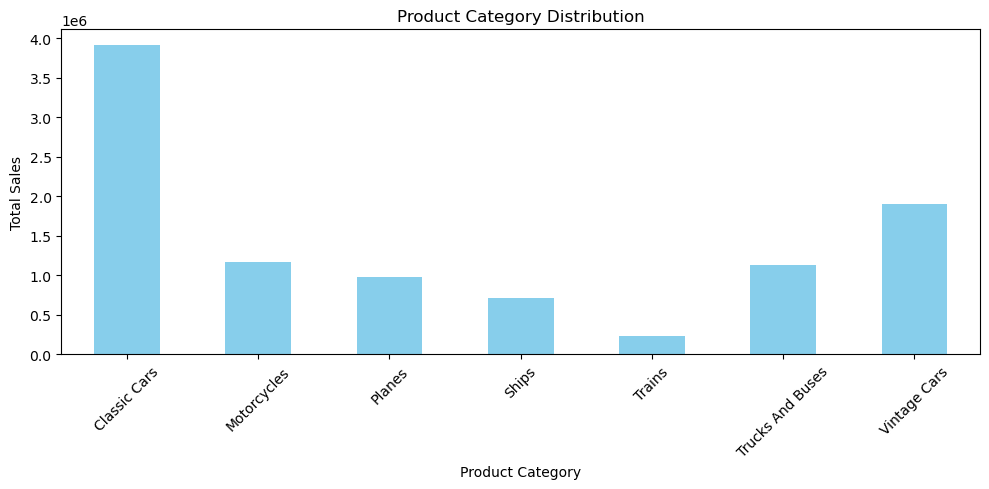

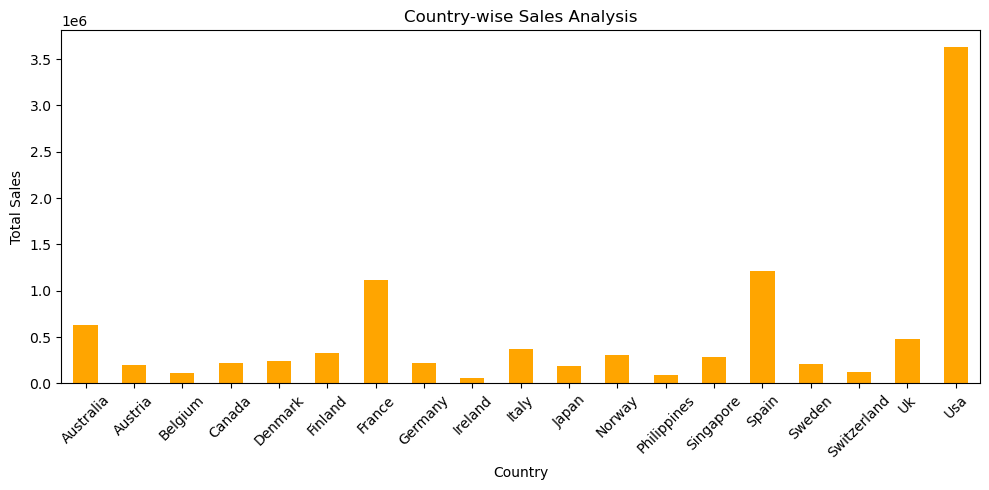

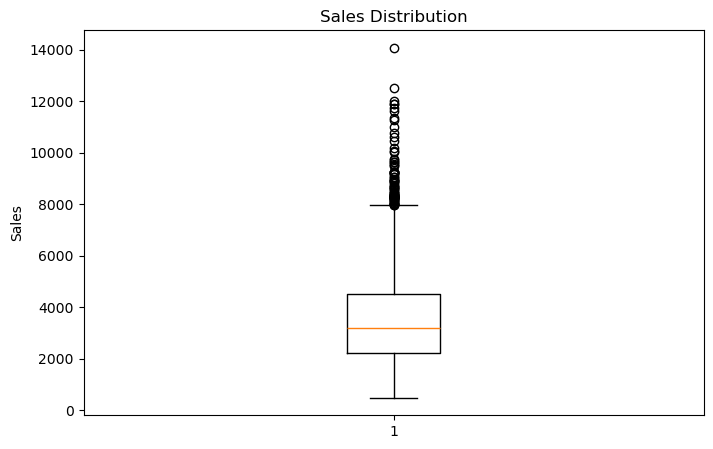

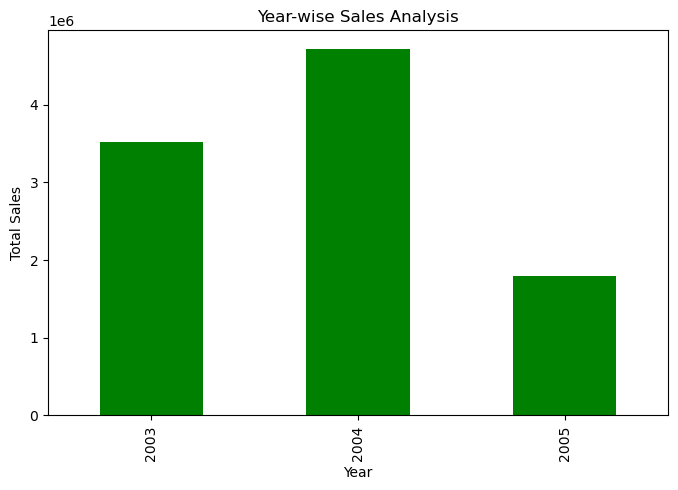

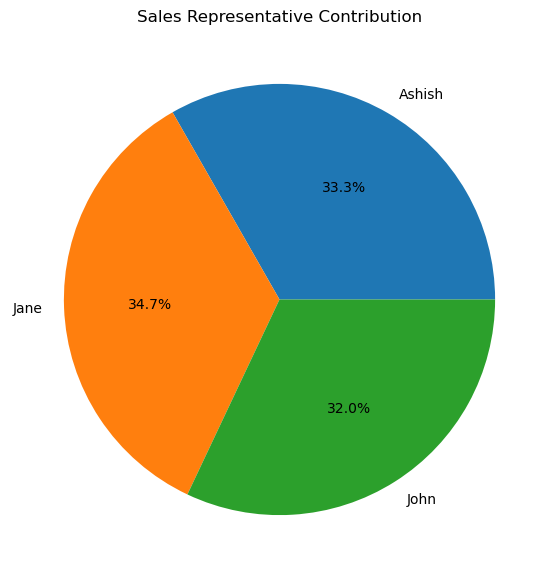


Sales Data Analysis Completed Successfully!


In [7]:

# Title: Analyzing Sales Data from Multiple File Formats

# Step 1: Import required libraries

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import json
import seaborn as sns


# Step 2: Load data from CSV, Excel and JSON files

csv = pd.read_csv(
    "./datasets/sales_data_sample.csv",
    encoding="cp1252"
)

ed = pd.read_excel(
    "./datasets/Sample-Sales-Data.xlsx"
)

with open("./datasets/customers.json", "r") as json_file:
    json_data = json.load(json_file)


# Step 3: Explore CSV dataset

print("CSV DATA")
print(csv.head())
print(csv.tail())

print("\nCSV INFORMATION")
csv.info()

print("\nCSV DESCRIPTIVE STATISTICS")
print(csv.describe())


# Step 4: Explore Excel dataset

print("\nEXCEL DATA")
print(ed.head())
print(ed.tail())

print("\nEXCEL INFORMATION")
ed.info()

print("\nEXCEL DESCRIPTIVE STATISTICS")
print(ed.describe())


# Step 5: Explore JSON dataset

json_df = pd.DataFrame(json_data)

print("\nJSON DATA")
print(json_df.head())

print("\nJSON INFORMATION")
json_df.info()

print("\nJSON DESCRIPTIVE STATISTICS")
print(json_df.describe(include="all"))


# Step 6: Check missing values

print("\nMissing values in CSV")
print(csv.isnull().sum())

print("\nMissing values in Excel")
print(ed.isnull().sum())

print("\nMissing values in JSON")
print(json_df.isnull().sum())


# Step 7: Remove duplicate records

csv = csv.drop_duplicates()
ed = ed.drop_duplicates()
json_df = json_df.drop_duplicates()


# Step 8: Handle missing values in CSV

csv["ADDRESSLINE2"] = csv["ADDRESSLINE2"].fillna("Not Available")
csv["STATE"] = csv["STATE"].fillna("Unknown")
csv["POSTALCODE"] = csv["POSTALCODE"].fillna("Unknown")
csv["TERRITORY"] = csv["TERRITORY"].fillna("Unknown")


# Step 9: Handle missing values in Excel

ed = ed.dropna()


# Step 10: Standardize data

csv["PRODUCTLINE"] = csv["PRODUCTLINE"].str.strip().str.title()
csv["COUNTRY"] = csv["COUNTRY"].str.strip().str.title()
csv["STATUS"] = csv["STATUS"].str.strip().str.title()


# Step 11: Convert data types

csv["ORDERDATE"] = pd.to_datetime(
    csv["ORDERDATE"],
    errors="coerce"
)

ed["Year"] = pd.to_numeric(ed["Year"], errors="coerce")
ed["Value"] = pd.to_numeric(ed["Value"], errors="coerce")


# Step 12: Data transformation

csv["TOTAL_AMOUNT"] = (
    csv["QUANTITYORDERED"] * csv["PRICEEACH"]
)

csv["MONTH"] = csv["ORDERDATE"].dt.month
csv["YEAR"] = csv["ORDERDATE"].dt.year


# Step 13: Calculate total sales

total_sales = csv["SALES"].sum()

print("\nTotal Sales:", total_sales)


# Step 14: Calculate average order value

average_order_value = (
    csv.groupby("ORDERNUMBER")["SALES"].sum().mean()
)

print("\nAverage Order Value:", average_order_value)


# Step 15: Product-wise sales analysis

product_sales = csv.groupby("PRODUCTLINE")["SALES"].sum()

print("\nProduct-wise Sales")
print(product_sales)


# Step 16: Country-wise sales analysis

country_sales = csv.groupby("COUNTRY")["SALES"].sum()

print("\nCountry-wise Sales")
print(country_sales)


# Step 17: Year-wise sales analysis

year_sales = csv.groupby("YEAR")["SALES"].sum()

print("\nYear-wise Sales")
print(year_sales)


# Step 18: Sales representative analysis using Excel data

rep_sales = ed.groupby("Sales_Rep_Name")["Value"].sum()

print("\nSales Representative Analysis")
print(rep_sales)


# Step 19: Visualization - Product category distribution

product_sales.plot(
    kind="bar",
    figsize=(10, 5),
    color="skyblue"
)

plt.title("Product Category Distribution")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Step 20: Visualization - Country-wise sales

country_sales.plot(
    kind="bar",
    figsize=(10, 5),
    color="orange"
)

plt.title("Country-wise Sales Analysis")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Step 21: Visualization - Sales distribution

plt.figure(figsize=(8, 5))

plt.boxplot(csv["SALES"])

plt.title("Sales Distribution")
plt.ylabel("Sales")
plt.show()


# Step 22: Visualization - Year-wise sales

year_sales.plot(
    kind="bar",
    figsize=(8, 5),
    color="green"
)

plt.title("Year-wise Sales Analysis")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.show()


# Step 23: Visualization - Sales representative performance

rep_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Sales Representative Contribution")
plt.ylabel("")
plt.show()


# Step 24: Save cleaned datasets

csv.to_csv("./datasets/cleaned_sales_data.csv", index=False)

ed.to_excel("./datasets/cleaned_excel_data.xlsx", index=False)

json_df.to_json(
    "./datasets/cleaned_customers.json",
    orient="records",
    indent=4
)

print("\nSales Data Analysis Completed Successfully!")
